In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, precision_recall_curve, roc_curve, 
                             roc_auc_score, average_precision_score)

In [2]:
# CONFIGS
RANDOM_STATE = 4200
NEGATIVE_RATIO = 1

ROOT_DIR = Path("leakage_free_70_30")
SPLIT_DIR = ROOT_DIR / "data_split"
CF_DIR = ROOT_DIR / "CF_scores"
OUTPUT_DIR = ROOT_DIR / "classifier_results"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# reading CF scores by quantile (leakage-free)

q60_df = pd.read_csv(CF_DIR / "predicted_CF_scores_Q60.csv")
q70_df = pd.read_csv(CF_DIR / "predicted_CF_scores_Q70.csv")
q80_df = pd.read_csv(CF_DIR / "predicted_CF_scores_Q80.csv")

print(f"Q60: {q60_df.shape}; Q70: {q70_df.shape}; Q80: {q80_df.shape}")

Q60: (121945, 22); Q70: (121945, 22); Q80: (121945, 22)


In [4]:
# identifying score columns
q60_scores = [c for c in q60_df.columns if c.startswith("Score_top60_")]
q70_scores = [c for c in q70_df.columns if c.startswith("Score_top70_")]
q80_scores = [c for c in q80_df.columns if c.startswith("Score_top80_")]

print(f"Number of score features per Q: Q60={len(q60_scores)}, Q70={len(q70_scores)}, Q80={len(q80_scores)}")

Number of score features per Q: Q60=20, Q70=20, Q80=20


In [5]:
# sanity checks
pair_cols = ["MiRNA", "Disease"]
assert q60_df[pair_cols].equals(q70_df[pair_cols])
assert q60_df[pair_cols].equals(q80_df[pair_cols])

print("Pair ordering is identical across Q60, Q70 and Q80.")

Pair ordering is identical across Q60, Q70 and Q80.


In [6]:
# concatenate scores column-wise
candidate_scores = pd.concat(
    [
        q60_df[pair_cols + q60_scores],
        q70_df[q70_scores],
        q80_df[q80_scores],
    ],
    axis=1
)

score_columns = q60_scores + q70_scores + q80_scores

print("Candidate score table:", candidate_scores.shape)
print("Candidate pairs:", len(candidate_scores))
print("CF features:", len(score_columns))

assert len(score_columns) == 60
assert candidate_scores.duplicated(pair_cols).sum() == 0
assert candidate_scores[score_columns].isna().sum().sum() == 0

candidate_scores.to_csv(CF_DIR / "predicted_CF_scores_Q60_Q70_Q80_combined.csv", index=False)

Candidate score table: (121945, 62)
Candidate pairs: 121945
CF features: 60


In [7]:
# loading predefined split
train_positive_pairs = pd.read_csv(SPLIT_DIR / "train_positive_pairs.csv")
heldout_positive_pairs = pd.read_csv(SPLIT_DIR / "heldout_positive_pairs.csv")
heldout_positive_scores_all = pd.read_csv(CF_DIR / "heldout_positive_CF_scores_complete.csv")

print("Training positives:", len(train_positive_pairs))
print("Held-out positives:", len(heldout_positive_pairs))
print("Held-out positives with complete CF scores:", len(heldout_positive_scores_all))

Training positives: 3801
Held-out positives: 1629
Held-out positives with complete CF scores: 1629


In [8]:
# Held-out positive scores for Q60, Q70 and Q80
heldout_positive_scores = heldout_positive_scores_all[pair_cols + score_columns].copy()

assert len(heldout_positive_scores) == len(heldout_positive_pairs)
assert heldout_positive_scores.duplicated(pair_cols).sum() == 0
assert heldout_positive_scores[score_columns].isna().sum().sum() == 0

print("Held-out positives:", len(heldout_positive_scores))

Held-out positives: 1629


In [9]:
# # final score features
# df = pd.read_csv("datasets/predicted_associations/CF_scores/predicted_multi_n_scores_Q60_Q70_Q80_finer_combined.csv")
# display(df)

In [10]:
# # analysis
# df.info()

In [11]:
# # analysis
# df.describe()

In [12]:
#loading ground-truths miRNA-disease associations

GROUND_TRUTH_FILE = ("datasets/1.miRNA_disease_association/knowndiseasemirnainteraction.txt")
ground_truth = pd.read_csv(
    GROUND_TRUTH_FILE,
    sep=r"\s+",
    header=None,
    names=["MiRNA", "Disease"]
).drop_duplicates()

print("Total known HMDD associations:", len(ground_truth))
assert len(ground_truth) == 5430

Total known HMDD associations: 5430


In [13]:
# marking training positives

train_positive_keys = set(
    map(
        tuple,
        train_positive_pairs[["MiRNA", "Disease"]].to_numpy()
    )
)

heldout_positive_keys = set(
    map(
        tuple,
        heldout_positive_pairs[["MiRNA", "Disease"]].to_numpy()
    )
)

known_keys = set(
    map(
        tuple,
        ground_truth[["MiRNA", "Disease"]].to_numpy()
    )
)

In [14]:
# classifying the randomly generated candidates
candidate_scores["pair_key"] = list(
    zip(
        candidate_scores["MiRNA"],
        candidate_scores["Disease"]
    )
)

train_positive_candidates = candidate_scores[candidate_scores["pair_key"].isin(train_positive_keys)].copy()
unobserved_candidates = candidate_scores[~candidate_scores["pair_key"].isin(known_keys)].copy()
print("Training positives naturally present in candidates:", len(train_positive_candidates))
print("Available unobserved candidate pairs:", len(unobserved_candidates))


Training positives naturally present in candidates: 2355
Available unobserved candidate pairs: 118595


In [15]:
# Sampling fixed test negatives
N_TEST_POS = len(heldout_positive_scores)
N_TEST_NEG = N_TEST_POS # 1:1

test_negative_candidates = unobserved_candidates.sample(n=N_TEST_NEG, random_state=RANDOM_STATE).copy()
print("Test positives:", N_TEST_POS)
print("Test negatives:", len(test_negative_candidates))

Test positives: 1629
Test negatives: 1629


In [16]:
#removing test negatives from training-negative candidate pool

test_negative_keys = set(test_negative_candidates["pair_key"])
train_negative_pool = unobserved_candidates[~unobserved_candidates["pair_key"].isin(test_negative_keys)].copy()

print("Original unobserved pool:", len(unobserved_candidates))
print("Reserved test negatives:", len(test_negative_candidates))
print("Remaining training-negative pool:", len(train_negative_pool))

Original unobserved pool: 118595
Reserved test negatives: 1629
Remaining training-negative pool: 116966


In [17]:
# sampling training negatives

NEGATIVE_RATIO = 1

N_TRAIN_POS = len(train_positive_candidates)
N_TRAIN_NEG = N_TRAIN_POS * NEGATIVE_RATIO

train_negative_candidates = train_negative_pool.sample(n=N_TRAIN_NEG, random_state=RANDOM_STATE).copy()
print("Training positives:", N_TRAIN_POS)
print("Training negatives:", len(train_negative_candidates))

Training positives: 2355
Training negatives: 2355


In [18]:
# constructing tje ML training dataset

train_positive_ml = train_positive_candidates[["MiRNA", "Disease"] + score_columns].copy()
train_negative_ml = train_negative_candidates[["MiRNA", "Disease"] + score_columns].copy()
train_positive_ml["Label"] = 1
train_negative_ml["Label"] = 0

train_df = pd.concat([train_positive_ml, train_negative_ml], ignore_index=True)

# Shuffle training observations only
train_df = train_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("\nTraining dataset:")
print(train_df["Label"].value_counts().sort_index())
print("Total:", len(train_df))


Training dataset:
Label
0    2355
1    2355
Name: count, dtype: int64
Total: 4710


In [19]:
# constructing ML test dataset

test_positive_ml = heldout_positive_scores[["MiRNA", "Disease"] + score_columns].copy()
test_negative_ml = test_negative_candidates[["MiRNA", "Disease"] + score_columns].copy()
test_positive_ml["Label"] = 1
test_negative_ml["Label"] = 0

test_df = pd.concat([test_positive_ml, test_negative_ml], ignore_index=True)

# Shuffle only for ordering
test_df = test_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("\nTest dataset:")
print(test_df["Label"].value_counts().sort_index())
print("Total:", len(test_df))


Test dataset:
Label
0    1629
1    1629
Name: count, dtype: int64
Total: 3258


In [20]:
# Train/test integrity checks
train_keys = set(zip(train_df["MiRNA"], train_df["Disease"]))
test_keys = set(zip(test_df["MiRNA"], test_df["Disease"]))

assert train_keys.isdisjoint(test_keys)
assert train_df.duplicated(["MiRNA", "Disease"]).sum() == 0
assert test_df.duplicated(["MiRNA", "Disease"]).sum() == 0
assert train_df[score_columns].isna().sum().sum() == 0
assert test_df[score_columns].isna().sum().sum() == 0
assert test_df["Label"].sum() == len(heldout_positive_pairs)

print("Train:", train_df.shape, "| Positives:", int(train_df["Label"].sum()))
print("Test:", test_df.shape, "| Positives:", int(test_df["Label"].sum()))

Train: (4710, 63) | Positives: 2355
Test: (3258, 63) | Positives: 1629


In [21]:
# ensuring none of the 1,629 held-out positives appears in training
heldout_keys = set(
    zip(
        heldout_positive_pairs["MiRNA"],
        heldout_positive_pairs["Disease"]
    )
)
assert len(train_keys.intersection(heldout_keys)) == 0
print("Held-out positives present in ML training set: 0")

Held-out positives present in ML training set: 0


In [22]:
# saving final datasets used for classification

ML_DATA_DIR = ROOT_DIR / "classifier_data"
ML_DATA_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(ML_DATA_DIR / "ML_train_Q60_Q70_Q80.csv", index=False)
test_df.to_csv(ML_DATA_DIR / "ML_test_Q60_Q70_Q80.csv", index=False)
print("Saved ML training and test datasets.")

Saved ML training and test datasets.


In [23]:
# defining the traing test splits 

X_train = train_df[score_columns].to_numpy(dtype=np.float32)
y_train = train_df["Label"].to_numpy(dtype=int)

X_test = test_df[score_columns].to_numpy(dtype=np.float32)
y_test = test_df["Label"].to_numpy(dtype=int)

print(f"X_train: {X_train.shape}; y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}; y_test: {y_test.shape}")

print("\nTrain classes:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest classes:")
print(pd.Series(y_test).value_counts().sort_index())

X_train: (4710, 60); y_train: (4710,)
X_test: (3258, 60); y_test: (3258,)

Train classes:
0    2355
1    2355
Name: count, dtype: int64

Test classes:
0    1629
1    1629
Name: count, dtype: int64


In [24]:
# Feature engineering: cumulative + incremental CF features

increment_columns = []
for q in [60, 70, 80]:
    for n in range(10, 101, 5):
        col = f"Increment_top{q}_n{n}"
        train_df[col] = (
            train_df[f"Score_top{q}_n{n}"]
            - train_df[f"Score_top{q}_n{n-5}"]
        )
        test_df[col] = (
            test_df[f"Score_top{q}_n{n}"]
            - test_df[f"Score_top{q}_n{n-5}"]
        )

        increment_columns.append(col)

enhanced_columns = score_columns + increment_columns
print(f"Features: {len(enhanced_columns)} ({len(score_columns)} cumulative + {len(increment_columns)} incremental)")

Features: 117 (60 cumulative + 57 incremental)


In [25]:
# enhanced matrices

X_train_enhanced = train_df[enhanced_columns].to_numpy(dtype=np.float32)
X_test_enhanced = test_df[enhanced_columns].to_numpy(dtype=np.float32)

print("Enhanced X_train:", X_train_enhanced.shape)
print("Enhanced X_test:", X_test_enhanced.shape)

assert np.isfinite(X_train_enhanced).all()
assert np.isfinite(X_test_enhanced).all()

Enhanced X_train: (4710, 117)
Enhanced X_test: (3258, 117)


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_enhanced)
X_test_scaled = scaler.transform(X_test_enhanced)

print("Scaled training:", X_train_scaled.shape)
print("Scaled test:", X_test_scaled.shape)

Scaled training: (4710, 117)
Scaled test: (3258, 117)


In [27]:
X_train_scaled, X_test_scaled

(array([[-0.4440324 , -0.57201594, -0.61221874, ..., -0.7722548 ,
         -0.7912374 , -0.7016083 ],
        [-0.4440324 , -0.57201594, -0.61221874, ..., -0.01774073,
          0.6705966 ,  1.0560495 ],
        [-0.4440324 , -0.57201594, -0.61221874, ...,  0.43845925,
          0.19469829,  0.03652164],
        ...,
        [-0.05103769, -0.30320382,  0.1621688 , ...,  0.62095106,
          1.6201802 ,  0.00431581],
        [-0.4440324 , -0.57201594, -0.61221874, ..., -0.7160007 ,
         -0.49786964, -0.7016083 ],
        [-0.4440324 , -0.57201594, -0.61221874, ..., -0.7722548 ,
         -0.7912374 , -0.7016083 ]], shape=(4710, 117), dtype=float32),
 array([[-0.4440324 ,  0.44924235,  0.75099474, ...,  2.9209487 ,
          0.5838776 ,  1.7876738 ],
        [ 0.10070164,  0.10449787,  0.05812756, ..., -0.29916513,
          0.12605189, -0.10572897],
        [ 0.90538293,  0.69144285,  0.7325737 , ...,  1.8981853 ,
          5.0881124 ,  3.1801262 ],
        ...,
        [-0.4440324 

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.ensemble import BaggingClassifier, VotingClassifier, ExtraTreesClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier

In [29]:
#helper functions

# plotting ROC and PR curves
def plot_sklearn_roc_curve(y_test, y_score):
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = roc_auc_score(y_test, y_score)

    precision, recall, _ = precision_recall_curve(y_test, y_score)
    auprc = average_precision_score(y_test, y_score)
    baseline_auprc = np.mean(y_test)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(fpr, tpr, label=f"AUROC = {roc_auc:.4f}")
    ax1.plot([0, 1], [0, 1], linestyle="--", label="Random")
    ax1.set_xlabel("False Positive Rate")
    ax1.set_ylabel("True Positive Rate")
    ax1.set_title("ROC curve")
    ax1.legend(loc="lower right")

    ax2.plot(recall, precision, label=f"AUPRC = {auprc:.4f}")
    ax2.axhline(baseline_auprc, linestyle="--", label=f"Baseline = {baseline_auprc:.4f}")
    ax2.set_xlabel("Recall")
    ax2.set_ylabel("Precision")
    ax2.set_title("Precision-recall curve")
    ax2.legend(loc="best")

    plt.tight_layout()
    plt.show()

    return roc_auc, auprc

# fitting classifier and evaluating against ground-truths
def classification_model(model, X_train, X_test, y_train, y_test, threshold=0.5):
    model.fit(X_train, y_train)

    y_score_train = model.predict_proba(X_train)[:, 1]
    y_score_test = model.predict_proba(X_test)[:, 1]

    # fixed threshold
    y_pred_train = (y_score_train >= threshold).astype(int)
    y_pred = (y_score_test >= threshold).astype(int)
    print(f"Classification threshold: {threshold:.4f}")

    # calculating accuracy
    training_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred)
    print(f"Training accuracy: {training_acc:.4f}")
    print(f"Test accuracy:     {test_acc:.4f}")

    # confucion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    print("\nConfusion matrix:")
    print(cm)

    fig, ax = plt.subplots(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=True, linewidths=.5, ax=ax)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"Confusion matrix (threshold = {threshold:.2f})")
    plt.tight_layout()
    plt.show()

    # classification report
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    # threshold-dependent metrics
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    precision_value = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall_value = sensitivity

    f1 = (
        2 * precision_value * recall_value /
        (precision_value + recall_value)
        if (precision_value + recall_value) > 0
        else 0.0
    )
    print(f"Sensitivity: {sensitivity:.4f}; Specificity: {specificity:.4f}")
    print(f"Precision: {precision_value:.4f}; Recall:      {recall_value:.4f}")
    print(f"F1-score: {f1:.4f}")

    # threshold-independent metrics
    roc_auc, auprc = plot_sklearn_roc_curve(y_test, y_score_test)
    print(f"\nAUROC: {roc_auc:.5f}")
    print(f"AUPRC: {auprc:.5f}")

    return {"Threshold": threshold, "Training Accuracy": training_acc, "Test Accuracy": test_acc, "Precision": precision_value,
            "Recall": recall_value, "F1": f1, "Sensitivity": sensitivity, "Specificity": specificity, "AUROC": roc_auc, "AUPRC": auprc,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

Classification threshold: 0.5000
Training accuracy: 0.7887
Test accuracy:     0.7124

Confusion matrix:
[[1486  143]
 [ 794  835]]


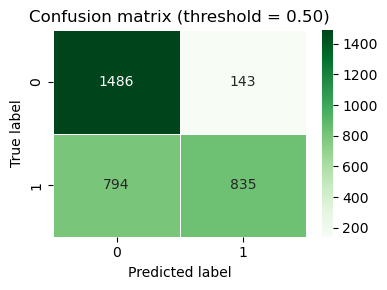


Classification report:
              precision    recall  f1-score   support

           0       0.65      0.91      0.76      1629
           1       0.85      0.51      0.64      1629

    accuracy                           0.71      3258
   macro avg       0.75      0.71      0.70      3258
weighted avg       0.75      0.71      0.70      3258

Sensitivity: 0.5126; Specificity: 0.9122
Precision: 0.8538; Recall:      0.5126
F1-score: 0.6406


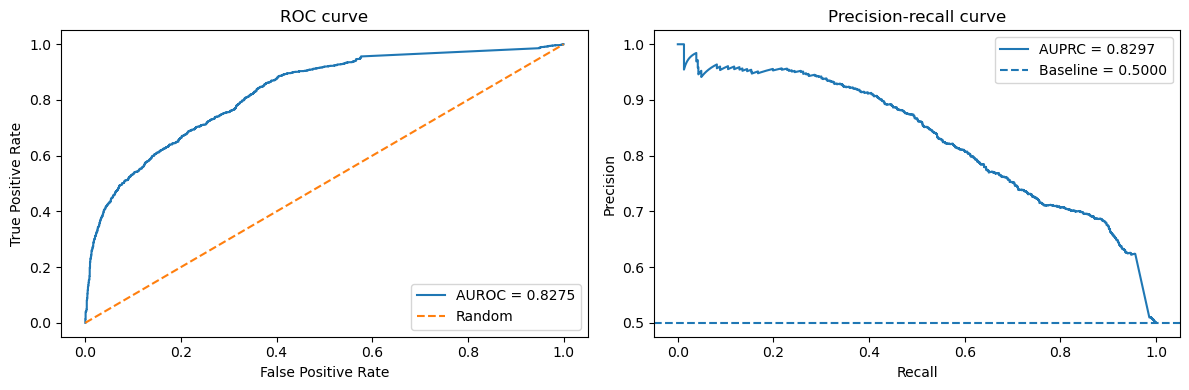


AUROC: 0.82752
AUPRC: 0.82971
Best LR parameters: {'estimator__C': 0.5, 'estimator__penalty': 'l2', 'estimator__solver': 'liblinear'}
Best CV AUPRC: 0.8921222576200135


In [30]:
# Logistic regression classifier

base_lr = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

lr_model = BaggingClassifier(
    estimator=base_lr,
    n_estimators=500,
    max_samples=0.40,
    max_features=0.30,
    bootstrap=True,
    bootstrap_features=True,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

lr_param_grid = {
    "estimator__C": [0.001, 0.5],
    "estimator__penalty": ["l1", "l2"],
    "estimator__solver": ["liblinear"],
}

lr_model_GS = GridSearchCV(
    estimator=lr_model,
    param_grid=lr_param_grid,
    cv=10,
    scoring={
        "AUROC": "roc_auc",
        "AUPRC": "average_precision"
    },
    refit="AUPRC",
    n_jobs=-1
)

lr_results = classification_model(
    lr_model_GS,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test,
    threshold=0.5
)

print("Best LR parameters:", lr_model_GS.best_params_)
print("Best CV AUPRC:", lr_model_GS.best_score_)

Fitting 10 folds for each of 108 candidates, totalling 1080 fits
[CV] END max_depth=2, max_features=0.2, min_samples_leaf=5, min_samples_split=10, n_estimators=5; total time=   0.1s
[CV] END max_depth=2, max_features=0.2, min_samples_leaf=5, min_samples_split=5, n_estimators=5; total time=   0.1s
[CV] END max_depth=2, max_features=0.2, min_samples_leaf=5, min_samples_split=5, n_estimators=5; total time=   0.1s
[CV] END max_depth=2, max_features=0.2, min_samples_leaf=5, min_samples_split=10, n_estimators=5; total time=   0.1s
[CV] END max_depth=2, max_features=0.2, min_samples_leaf=5, min_samples_split=5, n_estimators=5; total time=   0.1s
[CV] END max_depth=2, max_features=0.2, min_samples_leaf=5, min_samples_split=5, n_estimators=10; total time=   0.1s
[CV] END max_depth=2, max_features=0.2, min_samples_leaf=5, min_samples_split=10, n_estimators=5; total time=   0.1s
[CV] END max_depth=2, max_features=0.2, min_samples_leaf=5, min_samples_split=5, n_estimators=5; total time=   0.1s
[CV

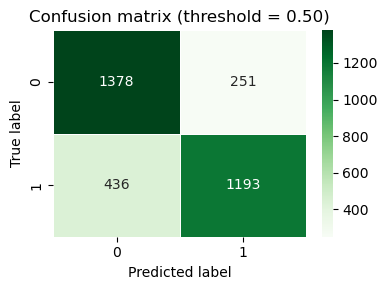


Classification report:
              precision    recall  f1-score   support

           0       0.76      0.85      0.80      1629
           1       0.83      0.73      0.78      1629

    accuracy                           0.79      3258
   macro avg       0.79      0.79      0.79      3258
weighted avg       0.79      0.79      0.79      3258

Sensitivity: 0.7324; Specificity: 0.8459
Precision: 0.8262; Recall:      0.7324
F1-score: 0.7764


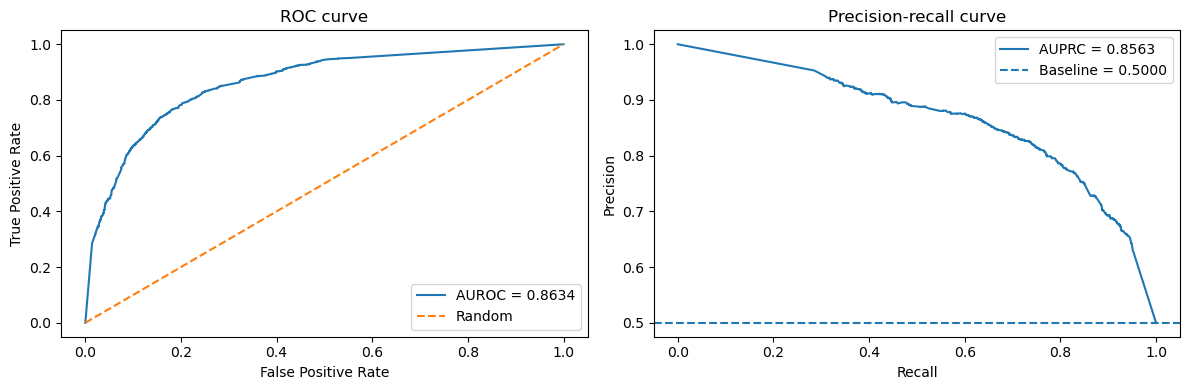


AUROC: 0.86341
AUPRC: 0.85635
Best Random Forest parameters: {'max_depth': 3, 'max_features': 0.6, 'min_samples_leaf': 15, 'min_samples_split': 5, 'n_estimators': 10}
Best CV AUPRC: 0.9059558840340959


In [31]:
# Random Forest classifier

rf_param_grid = {
    "n_estimators": [5, 10],
    "max_depth": [2, 3],
    "min_samples_leaf": [5, 10, 15],
    "min_samples_split": [5, 10, 20],
    "max_features": [0.2, 0.4, 0.6]
}

rf_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model_GS = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    cv=10,
    scoring={
        "AUROC": "roc_auc",
        "AUPRC": "average_precision"
    },
    refit="AUPRC",
    n_jobs=-1,
    verbose=2
)

rf_results = classification_model(
    rf_model_GS,
    X_train_enhanced,
    X_test_enhanced,
    y_train,
    y_test,
    threshold=0.5
)

print("Best Random Forest parameters:", rf_model_GS.best_params_)
print("Best CV AUPRC:", rf_model_GS.best_score_)

Classification threshold: 0.5000
Training accuracy: 0.9898
Test accuracy:     0.8011

Confusion matrix:
[[1400  229]
 [ 419 1210]]


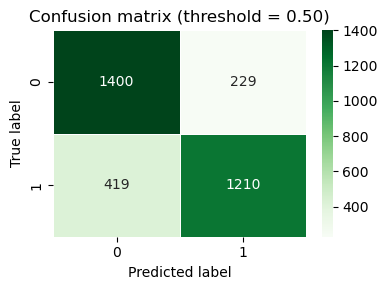


Classification report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81      1629
           1       0.84      0.74      0.79      1629

    accuracy                           0.80      3258
   macro avg       0.81      0.80      0.80      3258
weighted avg       0.81      0.80      0.80      3258

Sensitivity: 0.7428; Specificity: 0.8594
Precision: 0.8409; Recall:      0.7428
F1-score: 0.7888


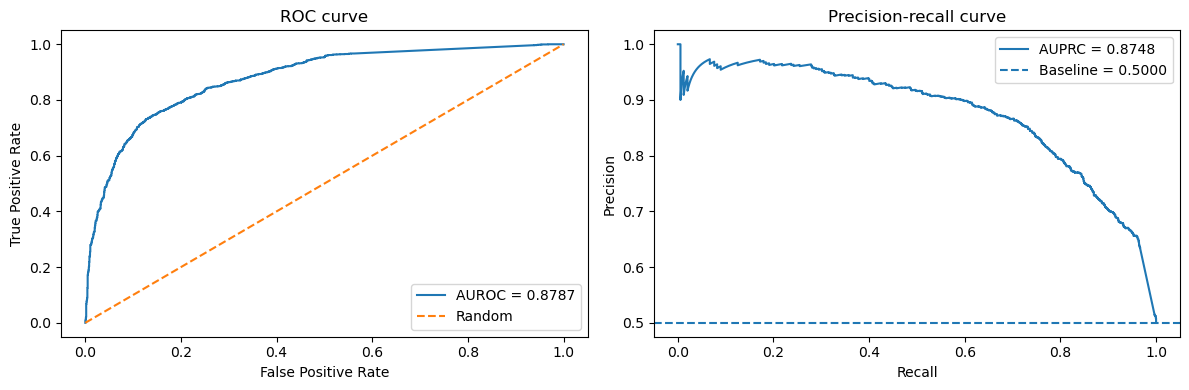


AUROC: 0.87871
AUPRC: 0.87478


In [32]:
# SVM-based ensemble classifier
# Hyperparameters fixed before evaluation on the leakage-free held-out set

svm = make_pipeline(
    PowerTransformer(),
    BaggingClassifier(
        estimator=SVC(
            kernel="rbf",
            C=500,
            gamma=0.05,
            class_weight={0: 1.0, 1: 1.5},
            probability=True,
            random_state=RANDOM_STATE
        ),
        n_estimators=100,
        max_features=1.0,
        max_samples=1.0,
        bootstrap=False,
        bootstrap_features=True,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
)

hgb = HistGradientBoostingClassifier(
    learning_rate=0.005,
    max_iter=1000,
    max_leaf_nodes=50,
    max_depth=None,
    min_samples_leaf=5,
    l2_regularization=0.70,
    random_state=RANDOM_STATE
)
enhanced_svm = VotingClassifier(
    estimators=[
        ("svm", svm),
        ("extra", ExtraTreesClassifier(
            n_estimators=100,
            max_features="sqrt",
            min_samples_leaf=2,
            max_depth=None,
            class_weight="balanced",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )),
        ("hgb", hgb)
    ],
    voting="soft",
    weights=[0.20, 0.30, 0.50], # SVM, ExtraTrees, HGB
    n_jobs=-1
)

svm_classifier_results = classification_model(
    enhanced_svm,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test,
    threshold=0.5
)

In [33]:
# Model performance summary table

results_df = pd.DataFrame({
    "Logistic Regression": lr_results,
    "Random Forest": rf_results,
    "SVM": svm_classifier_results,
}).T

display(results_df.round(4))

,Threshold,Training Accuracy,Test Accuracy,Precision,Recall,F1,Sensitivity,Specificity,AUROC,AUPRC,TN,FP,FN,TP
Logistic Regression,0.5,0.7887,0.7124,0.8538,0.5126,0.6406,0.5126,0.9122,0.8275,0.8297,1486.0,143.0,794.0,835.0
Random Forest,0.5,0.8367,0.7891,0.8262,0.7324,0.7764,0.7324,0.8459,0.8634,0.8563,1378.0,251.0,436.0,1193.0
SVM,0.5,0.9898,0.8011,0.8409,0.7428,0.7888,0.7428,0.8594,0.8787,0.8748,1400.0,229.0,419.0,1210.0


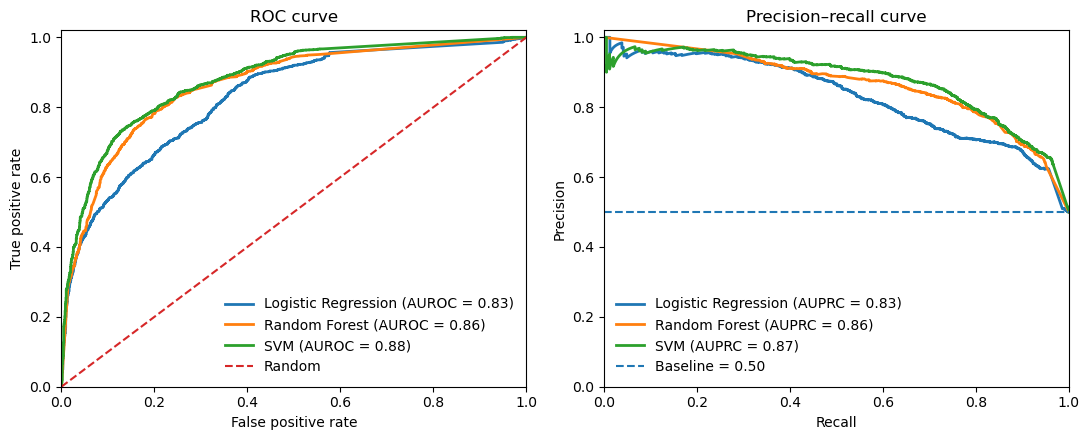

In [34]:
# performance curves (AUROC and AUPRC)
model_scores = {
    "Logistic Regression": lr_model_GS.predict_proba(X_test_scaled)[:, 1],
    "Random Forest": rf_model_GS.predict_proba(X_test_enhanced)[:, 1],
    "SVM": enhanced_svm.predict_proba(X_test_scaled)[:, 1],
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# ROC curves
ax = axes[0]
for model_name, y_score in model_scores.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    model_auc = roc_auc_score(y_test, y_score)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUROC = {model_auc:.2f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random"
)

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="lower right")


# Precision-recall curves
ax = axes[1]
for model_name, y_score in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    model_auprc = average_precision_score(y_test, y_score)
    ax.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (AUPRC = {model_auprc:.2f})"
    )

baseline_auprc = y_test.mean()

ax.axhline(
    baseline_auprc,
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline = {baseline_auprc:.2f}"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–recall curve")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="lower left")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "leakage_free_AUROC_AUPRC_curves.png", dpi=500, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "leakage_free_AUROC_AUPRC_curves.pdf", bbox_inches="tight")
plt.show()

In [35]:
# # saving pair-level leakage-free test predictions

# test_predictions = test_df[["MiRNA", "Disease", "Label"]].copy()
# test_predictions["LR_score"] = (lr_model_GS.predict_proba(X_test_scaled)[:, 1])
# test_predictions["RF_score"] = (rf_model_GS.predict_proba(X_test_enhanced)[:, 1])
# test_predictions["SVM_score"] = (enhanced_svm.predict_proba(X_test_enhanced)[:, 1])
# test_predictions["LR_prediction"] = (test_predictions["LR_score"] >= 0.5).astype(int)
# test_predictions["RF_prediction"] = (test_predictions["RF_score"] >= 0.5).astype(int)
# test_predictions["SVM_prediction"] = (test_predictions["SVM_score"] >= 0.5).astype(int)

# test_predictions.to_csv(OUTPUT_DIR / "leakage_free_test_pair_predictions.csv", index=False)

# print(test_predictions.shape)
# display(test_predictions.head())